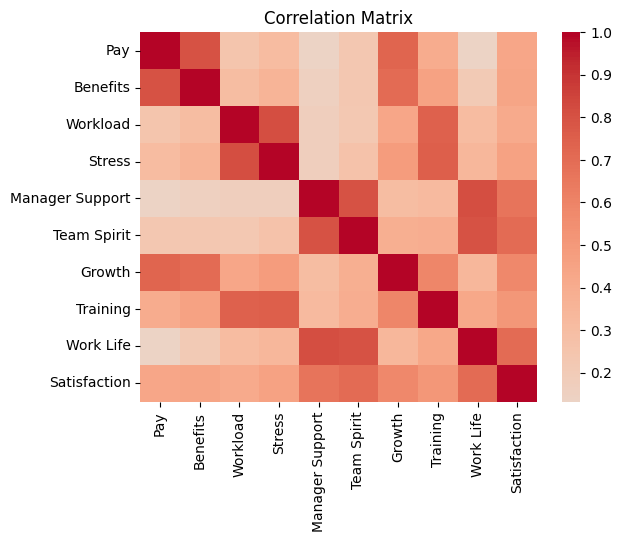

,Factor1,Factor2
Pay,0.34,0.24
Benefits,0.36,0.25
Workload,0.60,0.64
Stress,0.56,0.57
Manager Support,0.76,-0.47
Team Spirit,0.77,-0.35
Growth,0.48,0.24
Training,0.55,0.39
Work Life,0.69,-0.27
Satisfaction,0.60,-0.05


,Factor1,Factor2,Factor3
Pay,-0.52,0.42,-0.47
Benefits,-0.51,0.37,-0.36
Workload,-0.66,0.33,0.56
Stress,-0.62,0.31,0.43
Manager Support,-0.64,-0.62,-0.10
Team Spirit,-0.68,-0.49,-0.10
Growth,-0.59,0.26,-0.21
Training,-0.59,0.20,0.23
Work Life,-0.60,-0.45,0.03
Satisfaction,-0.60,-0.15,-0.07


,Factor1,Factor2,Factor3,Factor4
Pay,-0.52,0.37,-0.52,-0.02
Benefits,-0.51,0.33,-0.40,0.01
Workload,-0.69,0.33,0.50,-0.05
Stress,-0.65,0.31,0.40,-0.13
Manager Support,-0.61,-0.65,-0.08,0.05
Team Spirit,-0.65,-0.53,-0.09,0.01
Growth,-0.59,0.22,-0.25,0.01
Training,-0.62,0.20,0.22,0.19
Work Life,-0.58,-0.47,0.04,-0.03
Satisfaction,-0.58,-0.18,-0.09,-0.11


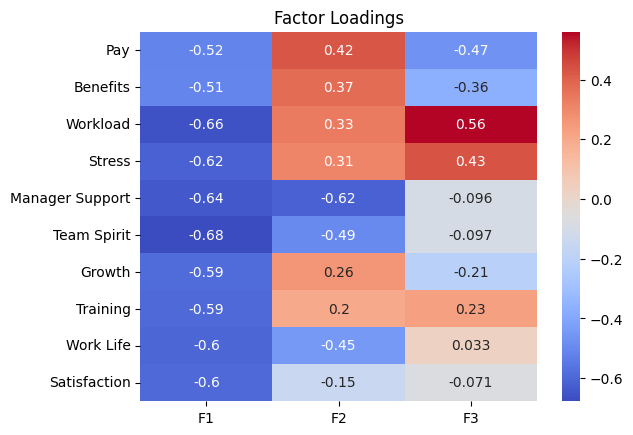

PCA Components Shape: (3, 10)


In [11]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import FactorAnalysis, PCA

np.random.seed(42)

Z = np.random.randn(300, 3)

L = np.array([
    [.9,.1,.1],
    [.8,.2,.1],
    [.1,.9,.1],
    [.2,.8,.1],
    [.1,.1,.9],
    [.2,.1,.8],
    [.6,.3,.2],
    [.2,.6,.2],
    [.1,.2,.7],
    [.3,.3,.5]
])

names = [
    "Pay", "Benefits", "Workload", "Stress",
    "Manager Support", "Team Spirit", "Growth",
    "Training", "Work Life", "Satisfaction"
]

X = Z @ L.T + 0.4*np.random.randn(300, 10)

df = pd.DataFrame(X, columns=names)

sns.heatmap(df.corr(), cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
plt.show()

for k in [2, 3, 4]:

    fa = FactorAnalysis(n_components=k).fit(df)

    display(pd.DataFrame(
        fa.components_.T,
        index=names,
        columns=[f"Factor{i+1}" for i in range(k)]
    ).round(2))

fa = FactorAnalysis(n_components=3).fit(df)

sns.heatmap(
    fa.components_.T,
    annot=True,
    xticklabels=["F1", "F2", "F3"],
    yticklabels=names,
    cmap="coolwarm"
)

plt.title("Factor Loadings")
plt.show()

pca = PCA(n_components=3).fit(df)

print("PCA Components Shape:", pca.components_.shape)
